In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
np.random.seed(42)

n = 2000

dates = pd.date_range(
    start="2020-01-01",
    periods=n,
    freq="D"
)

df = pd.DataFrame({
    "Date": dates,
    "Temperature_C": np.random.normal(27, 5, n),
    "Humidity_Percent": np.random.normal(65, 15, n),
    "Wind_Speed_kmh": np.random.normal(15, 6, n),
    "Rainfall_mm": np.random.exponential(4, n)
})

# Keep values realistic
df["Temperature_C"] = df["Temperature_C"].clip(10, 45).round(2)
df["Humidity_Percent"] = df["Humidity_Percent"].clip(20, 100).round(2)
df["Wind_Speed_kmh"] = df["Wind_Speed_kmh"].clip(2, 50).round(2)
df["Rainfall_mm"] = df["Rainfall_mm"].clip(0, 100).round(2)

# Create weather condition
df["Weather_Condition"] = np.select(
    [
        df["Rainfall_mm"] > 15,
        df["Rainfall_mm"] > 5,
        df["Temperature_C"] >= 35,
        df["Temperature_C"] <= 18
    ],
    [
        "Heavy Rain",
        "Rainy",
        "Hot",
        "Cool"
    ],
    default="Clear"
)

df.head()

,Date,Temperature_C,Humidity_Percent,Wind_Speed_kmh,Rainfall_mm,Weather_Condition
0,2020-01-01,29.48,54.87,9.82,1.64,Clear
1,2020-01-02,26.31,62.83,14.81,0.95,Clear
2,2020-01-03,30.24,53.11,15.11,1.50,Clear
3,2020-01-04,34.62,60.38,17.84,0.79,Clear
4,2020-01-05,25.83,36.60,6.80,9.29,Rainy


In [3]:
print("Dataset Shape:", df.shape)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:", df.duplicated().sum())

print("\nData Types:")
print(df.dtypes)

print("\nBasic Statistics:")
display(df.describe())

Dataset Shape: (2000, 6)

Missing Values:
Date                 0
Temperature_C        0
Humidity_Percent     0
Wind_Speed_kmh       0
Rainfall_mm          0
Weather_Condition    0
dtype: int64

Duplicate Rows: 0

Data Types:
Date                 datetime64[us]
Temperature_C               float64
Humidity_Percent            float64
Wind_Speed_kmh              float64
Rainfall_mm                 float64
Weather_Condition               str
dtype: object

Basic Statistics:


,Date,Temperature_C,Humidity_Percent,Wind_Speed_kmh,Rainfall_mm
count,2000,2000.000000,2000.000000,2000.000000,2000.000000
mean,2022-09-26 12:00:00,27.224825,64.846550,14.754425,3.763520
min,2020-01-01 00:00:00,10.790000,20.000000,2.000000,0.000000
25%,2021-05-14 18:00:00,23.890000,54.360000,10.880000,1.160000
50%,2022-09-26 12:00:00,27.225000,65.000000,14.815000,2.630000
75%,2024-02-08 06:00:00,30.415000,74.982500,18.775000,5.160000
max,2025-06-22 00:00:00,45.000000,100.000000,33.680000,26.330000
std,NaN,4.940005,14.923331,5.894589,3.666091


In [4]:
df["Year"] = df["Date"].dt.year
df["Month"] = df["Date"].dt.month
df["Month_Name"] = df["Date"].dt.month_name()

# Define seasons
df["Season"] = np.select(
    [
        df["Month"].isin([12, 1, 2]),
        df["Month"].isin([3, 4, 5]),
        df["Month"].isin([6, 7, 8, 9]),
        df["Month"].isin([10, 11])
    ],
    [
        "Winter",
        "Summer",
        "Monsoon",
        "Post-Monsoon"
    ],
    default="Unknown"
)

df.head()

,Date,Temperature_C,Humidity_Percent,Wind_Speed_kmh,Rainfall_mm,Weather_Condition,Year,Month,Month_Name,Season
0,2020-01-01,29.48,54.87,9.82,1.64,Clear,2020,1,January,Winter
1,2020-01-02,26.31,62.83,14.81,0.95,Clear,2020,1,January,Winter
2,2020-01-03,30.24,53.11,15.11,1.50,Clear,2020,1,January,Winter
3,2020-01-04,34.62,60.38,17.84,0.79,Clear,2020,1,January,Winter
4,2020-01-05,25.83,36.60,6.80,9.29,Rainy,2020,1,January,Winter


In [5]:
monthly_weather = df.groupby(["Month", "Month_Name"]).agg(
    Average_Temperature=("Temperature_C", "mean"),
    Median_Temperature=("Temperature_C", "median"),
    Total_Rainfall=("Rainfall_mm", "sum"),
    Average_Humidity=("Humidity_Percent", "mean"),
    Average_Wind_Speed=("Wind_Speed_kmh", "mean")
).reset_index()

monthly_weather = monthly_weather.sort_values("Month")

monthly_weather.round(2)

,Month,Month_Name,Average_Temperature,Median_Temperature,Total_Rainfall,Average_Humidity,Average_Wind_Speed
0,1,January,27.11,27.24,684.98,63.18,14.27
1,2,February,27.63,27.59,630.11,63.42,14.47
2,3,March,26.93,26.83,712.52,64.28,14.28
3,4,April,26.80,26.55,744.44,66.70,14.96
4,5,May,27.15,26.92,735.64,65.12,15.79
5,6,June,27.68,28.03,655.35,65.00,14.77
6,7,July,27.27,27.77,543.55,65.83,15.36
7,8,August,27.48,27.63,552.94,65.39,14.68
8,9,September,26.79,26.91,525.16,65.57,14.17
9,10,October,27.54,27.35,671.58,64.07,14.40


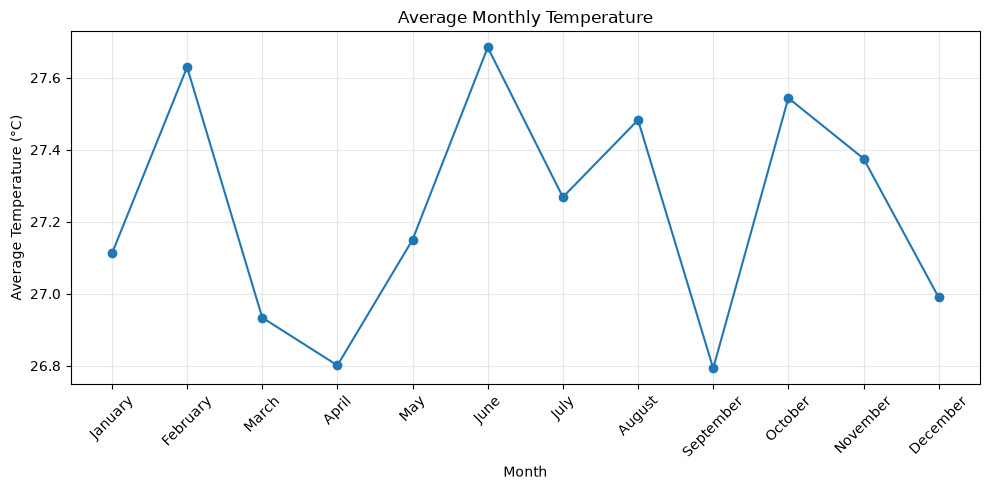

In [6]:
plt.figure(figsize=(10, 5))

plt.plot(
    monthly_weather["Month_Name"],
    monthly_weather["Average_Temperature"],
    marker="o"
)

plt.title("Average Monthly Temperature")
plt.xlabel("Month")
plt.ylabel("Average Temperature (°C)")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(
    r"C:\Users\durga\OneDrive\Desktop\data-analysis-portfolio\visualizations\monthly_temperature.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

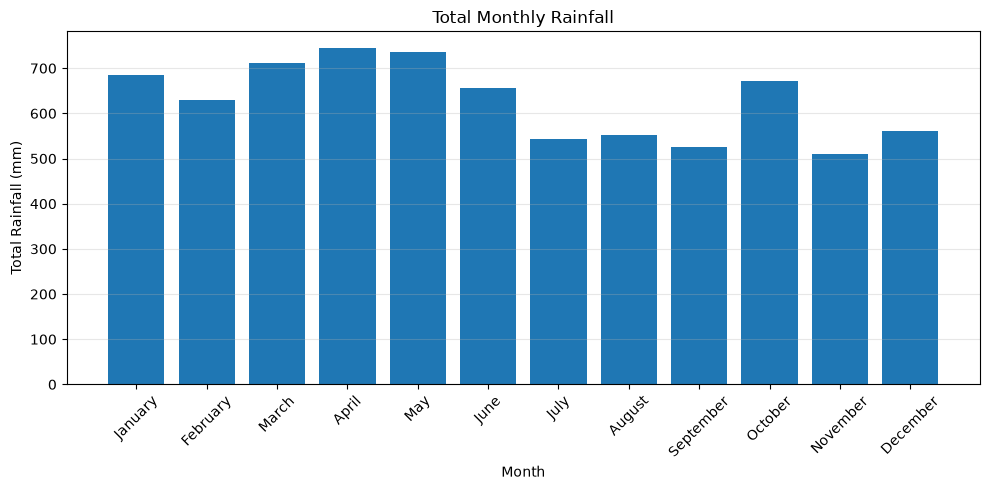

In [7]:
plt.figure(figsize=(10, 5))

plt.bar(
    monthly_weather["Month_Name"],
    monthly_weather["Total_Rainfall"]
)

plt.title("Total Monthly Rainfall")
plt.xlabel("Month")
plt.ylabel("Total Rainfall (mm)")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    r"C:\Users\durga\OneDrive\Desktop\data-analysis-portfolio\visualizations\monthly_rainfall.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [8]:
seasonal_weather = df.groupby("Season").agg(
    Average_Temperature=("Temperature_C", "mean"),
    Median_Temperature=("Temperature_C", "median"),
    Total_Rainfall=("Rainfall_mm", "sum"),
    Average_Humidity=("Humidity_Percent", "mean"),
    Average_Wind_Speed=("Wind_Speed_kmh", "mean")
).reset_index()

# Arrange seasons in logical order
season_order = ["Winter", "Summer", "Monsoon", "Post-Monsoon"]

seasonal_weather["Season"] = pd.Categorical(
    seasonal_weather["Season"],
    categories=season_order,
    ordered=True
)

seasonal_weather = seasonal_weather.sort_values("Season")

seasonal_weather.round(2)

,Season,Average_Temperature,Median_Temperature,Total_Rainfall,Average_Humidity,Average_Wind_Speed
3,Winter,27.25,27.23,1875.79,63.89,14.59
2,Summer,26.96,26.82,2192.60,65.35,15.01
0,Monsoon,27.32,27.52,2277.00,65.43,14.75
1,Post-Monsoon,27.46,27.35,1181.65,64.32,14.57


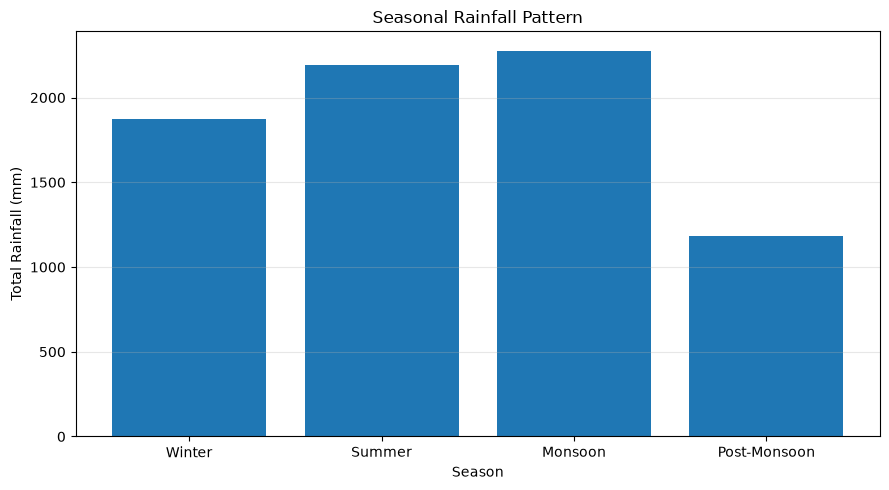

In [9]:
plt.figure(figsize=(9, 5))

plt.bar(
    seasonal_weather["Season"],
    seasonal_weather["Total_Rainfall"]
)

plt.title("Seasonal Rainfall Pattern")
plt.xlabel("Season")
plt.ylabel("Total Rainfall (mm)")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    r"C:\Users\durga\OneDrive\Desktop\data-analysis-portfolio\visualizations\seasonal_rainfall.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [10]:
extreme_events = df[
    (df["Temperature_C"] >= 40) |
    (df["Temperature_C"] <= 15) |
    (df["Rainfall_mm"] >= 20) |
    (df["Wind_Speed_kmh"] >= 30)
].copy()

print("Total Extreme Weather Events:", len(extreme_events))

print("\nExtreme Heat Events:", (df["Temperature_C"] >= 40).sum())
print("Extreme Cold Events:", (df["Temperature_C"] <= 15).sum())
print("Heavy Rain Events:", (df["Rainfall_mm"] >= 20).sum())
print("High Wind Events:", (df["Wind_Speed_kmh"] >= 30).sum())

print("\nExtreme Weather Events:")
display(
    extreme_events[
        [
            "Date",
            "Temperature_C",
            "Humidity_Percent",
            "Wind_Speed_kmh",
            "Rainfall_mm",
            "Weather_Condition"
        ]
    ].sort_values("Date")
)

Total Extreme Weather Events: 48

Extreme Heat Events: 8
Extreme Cold Events: 17
Heavy Rain Events: 8
High Wind Events: 15

Extreme Weather Events:


,Date,Temperature_C,Humidity_Percent,Wind_Speed_kmh,Rainfall_mm,Weather_Condition
47,2020-02-17,32.29,64.86,31.89,5.60,Rainy
74,2020-03-15,13.90,55.74,12.32,3.82,Cool
92,2020-04-02,23.49,74.33,14.32,22.84,Heavy Rain
179,2020-06-28,40.60,65.10,12.94,10.32,Rainy
209,2020-07-28,45.00,64.99,8.24,11.29,Rainy
262,2020-09-19,10.79,83.54,19.56,7.31,Rainy
478,2021-04-23,42.39,44.92,6.63,12.03,Rainy
544,2021-06-28,14.64,100.00,17.22,0.44,Cool
575,2021-07-29,15.94,48.32,13.67,21.89,Heavy Rain
646,2021-10-08,13.52,59.44,6.64,2.13,Cool


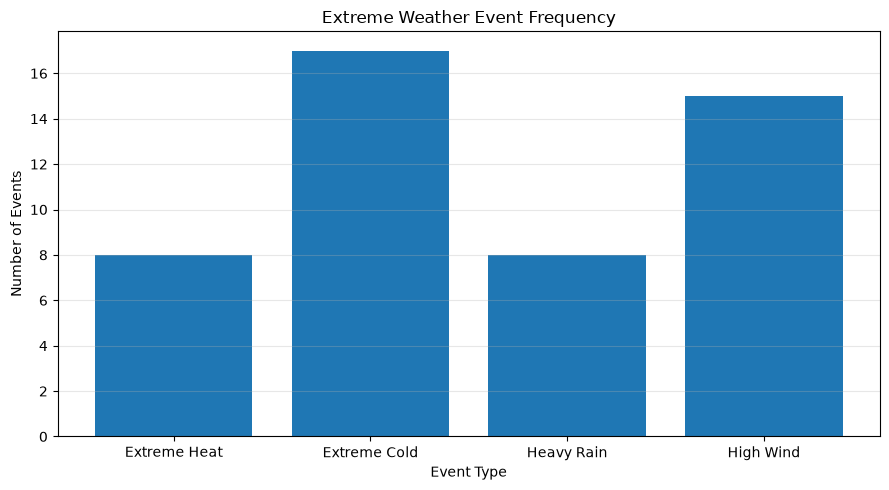

In [11]:
extreme_counts = pd.Series({
    "Extreme Heat": (df["Temperature_C"] >= 40).sum(),
    "Extreme Cold": (df["Temperature_C"] <= 15).sum(),
    "Heavy Rain": (df["Rainfall_mm"] >= 20).sum(),
    "High Wind": (df["Wind_Speed_kmh"] >= 30).sum()
})

plt.figure(figsize=(9, 5))

plt.bar(
    extreme_counts.index,
    extreme_counts.values
)

plt.title("Extreme Weather Event Frequency")
plt.xlabel("Event Type")
plt.ylabel("Number of Events")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    r"C:\Users\durga\OneDrive\Desktop\data-analysis-portfolio\visualizations\extreme_weather_events.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [12]:
weather_numeric = df[
    [
        "Temperature_C",
        "Humidity_Percent",
        "Wind_Speed_kmh",
        "Rainfall_mm"
    ]
]

weather_correlation = weather_numeric.corr()

print("Weather Correlation Matrix:")
display(weather_correlation.round(3))

Weather Correlation Matrix:


,Temperature_C,Humidity_Percent,Wind_Speed_kmh,Rainfall_mm
Temperature_C,1.000,-0.018,-0.004,0.001
Humidity_Percent,-0.018,1.000,0.035,0.006
Wind_Speed_kmh,-0.004,0.035,1.000,0.034
Rainfall_mm,0.001,0.006,0.034,1.000


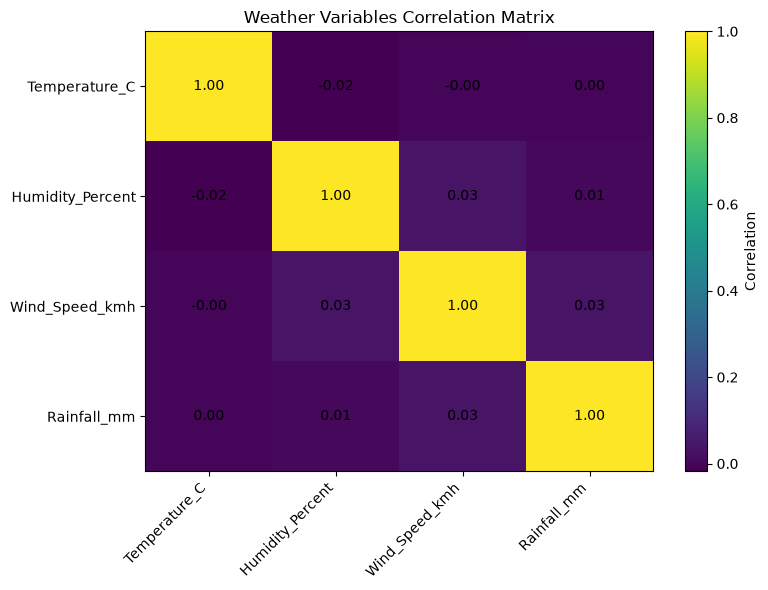

In [13]:
plt.figure(figsize=(8, 6))

plt.imshow(
    weather_correlation,
    interpolation="nearest",
    aspect="auto"
)

plt.colorbar(label="Correlation")

plt.xticks(
    range(len(weather_correlation.columns)),
    weather_correlation.columns,
    rotation=45,
    ha="right"
)

plt.yticks(
    range(len(weather_correlation.index)),
    weather_correlation.index
)

for i in range(len(weather_correlation.index)):
    for j in range(len(weather_correlation.columns)):
        plt.text(
            j,
            i,
            f"{weather_correlation.iloc[i, j]:.2f}",
            ha="center",
            va="center"
        )

plt.title("Weather Variables Correlation Matrix")
plt.tight_layout()

plt.savefig(
    r"C:\Users\durga\OneDrive\Desktop\data-analysis-portfolio\visualizations\weather_correlation_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

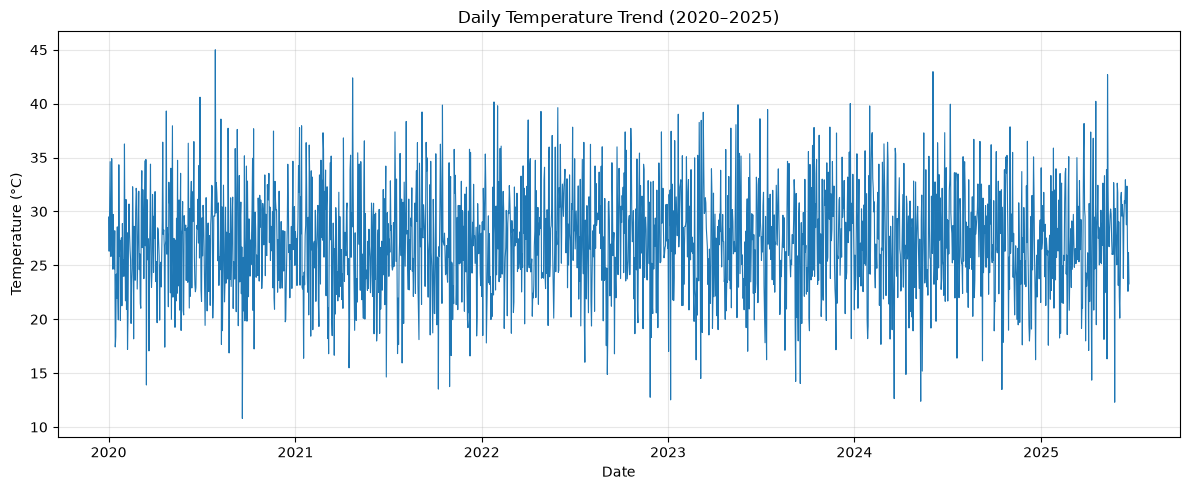

In [14]:
plt.figure(figsize=(12, 5))

plt.plot(
    df["Date"],
    df["Temperature_C"],
    linewidth=0.8
)

plt.title("Daily Temperature Trend (2020–2025)")
plt.xlabel("Date")
plt.ylabel("Temperature (°C)")
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(
    r"C:\Users\durga\OneDrive\Desktop\data-analysis-portfolio\visualizations\temperature_trend.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [15]:
statistical_summary = df[
    [
        "Temperature_C",
        "Humidity_Percent",
        "Wind_Speed_kmh",
        "Rainfall_mm"
    ]
].agg(["mean", "median", "min", "max"]).T

statistical_summary = statistical_summary.round(2)

print("Weather Statistical Summary:")
display(statistical_summary)

Weather Statistical Summary:


,mean,median,min,max
Temperature_C,27.22,27.22,10.79,45.00
Humidity_Percent,64.85,65.00,20.00,100.00
Wind_Speed_kmh,14.75,14.82,2.00,33.68
Rainfall_mm,3.76,2.63,0.00,26.33


In [16]:
portfolio_data = r"C:\Users\durga\OneDrive\Desktop\data-analysis-portfolio\data"

os.makedirs(portfolio_data, exist_ok=True)

file_path = os.path.join(portfolio_data, "weather_data.csv")

df.to_csv(file_path, index=False)

print("Weather dataset saved successfully!")
print("File:", file_path)
print("Exists:", os.path.exists(file_path))

Weather dataset saved successfully!
File: C:\Users\durga\OneDrive\Desktop\data-analysis-portfolio\data\weather_data.csv
Exists: True


In [17]:
weather_condition_counts = (
    df["Weather_Condition"]
    .value_counts()
    .rename_axis("Weather_Condition")
    .reset_index(name="Days")
)

weather_condition_counts

,Weather_Condition,Days
0,Clear,1348
1,Rainy,494
2,Hot,83
3,Cool,43
4,Heavy Rain,32


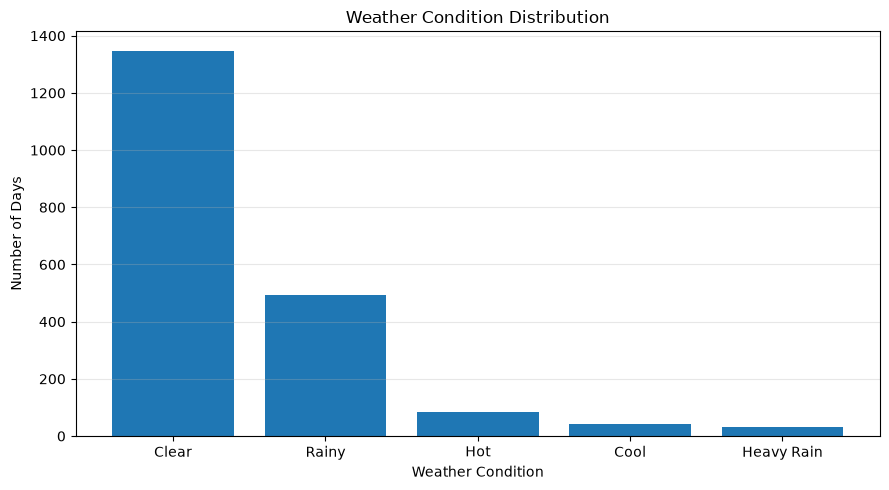

In [18]:
plt.figure(figsize=(9, 5))

plt.bar(
    weather_condition_counts["Weather_Condition"],
    weather_condition_counts["Days"]
)

plt.title("Weather Condition Distribution")
plt.xlabel("Weather Condition")
plt.ylabel("Number of Days")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    r"C:\Users\durga\OneDrive\Desktop\data-analysis-portfolio\visualizations\weather_condition_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [20]:
print("========== FINAL DATA QUALITY CHECK ==========")

print("\nDataset Shape:", df.shape)

print("\nMissing Values:")
print(df.isnull().sum().sum())

print("\nDuplicate Rows:", df.duplicated().sum())

print("\nUnique Dates:", df["Date"].nunique())

print("\nDate Range:")
print(df["Date"].min(), "to", df["Date"].max())

print("\nTemperature Range:")
print(df["Temperature_C"].min(), "to", df["Temperature_C"].max())

print("\nRainfall Range:")
print(df["Rainfall_mm"].min(), "to", df["Rainfall_mm"].max())

print("\nWeather Conditions:")
print(df["Weather_Condition"].value_counts())

========== FINAL DATA QUALITY CHECK ==========

Dataset Shape: (2000, 10)

Missing Values:
0

Duplicate Rows: 0

Unique Dates: 2000

Date Range:
2020-01-01 00:00:00 to 2025-06-22 00:00:00

Temperature Range:
10.79 to 45.0

Rainfall Range:
0.0 to 26.33

Weather Conditions:
Weather_Condition
Clear         1348
Rainy          494
Hot             83
Cool            43
Heavy Rain      32
Name: count, dtype: int64


# Insights & Recommendations

## Key Insights

### 1. Temperature Patterns
- The overall average temperature is **27.22°C**, with a median of **27.22°C**.
- Monthly average temperatures remain relatively stable throughout the year, ranging from **26.79°C to 27.68°C**.
- The highest monthly average temperature occurs in **June (27.68°C)**.
- The lowest monthly average temperature occurs in **September (26.79°C)**.
- The dataset records temperatures ranging from **10.79°C to 45.00°C**, showing occasional extreme temperature conditions.

### 2. Rainfall Patterns
- Average daily rainfall is **3.76 mm**, while the median is **2.63 mm**.
- **April** has the highest total monthly rainfall at **744.44 mm**.
- **November** has the lowest total monthly rainfall at **510.07 mm**.
- The **Monsoon season** records the highest seasonal rainfall at **2,277.00 mm**.
- Heavy rainfall events (rainfall ≥ 20 mm) occurred on **32 days**.

### 3. Seasonal Patterns
- **Post-Monsoon** has the highest average temperature at **27.46°C**.
- **Summer** has the lowest average temperature at **26.96°C** in this simulated dataset.
- **Monsoon** has the highest total rainfall (**2,277.00 mm**) and highest average humidity (**65.43%**).
- **Post-Monsoon** has the lowest seasonal rainfall (**1,181.65 mm**).

### 4. Weather Conditions
- Clear weather represents **67.4%** of all recorded days.
- Rainy conditions represent **24.7%** of days.
- Hot conditions represent **4.15%** of days.
- Cool conditions represent **2.15%** of days.
- Heavy rain represents **1.6%** of days.

### 5. Extreme Weather Events
- **48 extreme-weather records** were identified using predefined thresholds.
- There were **8 extreme heat events**.
- There were **17 extreme cold events**.
- There were **8 heavy rainfall events**.
- There were **15 high-wind events**.
- Extreme cold was the most frequently observed individual extreme category.

### 6. Correlation Analysis
- Temperature and rainfall show an almost zero correlation (**0.001**).
- Temperature and humidity have a correlation of **-0.018**.
- Wind speed and rainfall have a correlation of **0.034**.
- Overall, the weather variables show **very weak linear relationships** in this simulated dataset.

## Business & Operational Recommendations

1. **Plan operations around seasonal rainfall**
   - Increase preparedness during the Monsoon season because it records the highest rainfall.
   - Consider weather-related contingency planning for outdoor operations and logistics.

2. **Prepare for extreme weather**
   - Establish alerts and contingency procedures for extreme heat, cold, heavy rain, and high winds.
   - Review operational schedules when extreme conditions are forecast.

3. **Optimize resource planning**
   - Use historical weather patterns to plan staffing, transportation, outdoor activities, and infrastructure maintenance.
   - Give additional attention to months with higher rainfall.

4. **Rainfall monitoring**
   - Monitor rainfall levels closely during periods with historically higher rainfall.
   - Maintain drainage and water-management infrastructure to reduce disruption risk.

5. **Use weather data for forecasting**
   - Continue collecting daily weather data and combine it with external factors for better predictive models.
   - Future analysis could include air pressure, cloud cover, solar radiation, and location-specific weather information.

## Conclusion

This analysis examined temperature trends, rainfall patterns, seasonal variation, weather-condition frequency, extreme weather events, and correlations between major weather variables.

The dataset shows relatively stable temperatures, significant seasonal rainfall variation, and a predominance of clear weather conditions. The analysis also identified 48 extreme-weather records that can be used to support operational preparedness.

Because the dataset is simulated, the findings should be treated as an analytical demonstration rather than real-world weather forecasting. In a production environment, the same methodology can be applied to reliable government or meteorological datasets.